# 1. Selección del conjunto de datos


## 1.1. Elección y justificación

Hemos elegido el conjunto de datos **Intel Image Classification**, disponible en Kaggle con el identificador `puneet6060/intel-image-classification`.

Nuestro objetivo es clasificar cada imagen en una de las seis categorías disponibles: edificios (`buildings`), bosque (`forest`), glaciar (`glacier`), montaña (`mountain`), mar (`sea`) y calle (`street`). Para ello, utilizaremos como variable objetivo la categoría asociada a la carpeta en la que se encuentra cada imagen.

Consideramos que este conjunto de datos es adecuado para nuestro trabajo porque nos permite comparar los resultados de una red neuronal convolucional (CNN) diseñada y entrenada desde cero con los obtenidos mediante una red preentrenada. Además, las imágenes presentan diferencias de color, textura y estructura, así como ciertas similitudes entre categorías que pueden dificultar su clasificación, como ocurre, por ejemplo, entre montaña y glaciar o entre edificios y calle.

El conjunto de datos incluye particiones etiquetadas de entrenamiento y test. En este apartado comprobaremos el número real de imágenes disponibles en cada una de ellas para valorar si el volumen de datos es suficiente para llevar a cabo el entrenamiento y la evaluación de los modelos. De este modo, partiremos de los datos disponibles sin presuponer de antemano el rendimiento que podremos alcanzar. En caso de encontrar imágenes sin etiquetar en la carpeta `seg_pred`, las contabilizaremos por separado y no las utilizaremos para evaluar los modelos.

**Fuente del conjunto de datos:** [Intel Image Classification en Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification).

## 1.2. Dependencias

In [ ]:
%pip install -q --upgrade kaggle
%pip install -q pandas pillow matplotlib tqdm

In [ ]:
import os
import sys
import json
import hashlib
import subprocess
import importlib.util
from pathlib import Path
import getpass
from datetime import datetime, timezone
from importlib.metadata import version
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, Markdown

SEMILLA = 42
CLASES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
NOMBRES = dict(zip(CLASES, ['Edificios', 'Bosque', 'Glaciar', 'Montaña', 'Mar', 'Calle']))
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

## 1.3. Carga local o descarga autenticada

Primero descargamos de Kaggle una sola vez el dataset, para ello, se requiere de un token personal de Kaggle.

In [ ]:
DATASET = 'puneet6060/intel-image-classification'
DATOS = Path.cwd() / 'apartado1' / 'datos'
DATOS.mkdir(parents=True, exist_ok=True)

# Introducimos el token sin mostrarlo ni guardarlo en el notebook.
token = getpass.getpass('Introduce tu token de Kaggle: ').strip()

if not token:
    raise ValueError('No se ha introducido ningún token.')

# Pasamos la credencial únicamente al proceso de descarga.
entorno = os.environ.copy()
entorno['KAGGLE_API_TOKEN'] = token

try:
    # Localizamos el cliente instalado en el entorno del notebook.
    spec = importlib.util.find_spec('kaggle')

    if spec is None or not spec.submodule_search_locations:
        raise RuntimeError('Ejecuta primero la celda de instalación de Kaggle.')

    cli = Path(next(iter(spec.submodule_search_locations))) / 'cli.py'

    if not cli.is_file():
        raise RuntimeError('No se encuentra el cliente de Kaggle. Reinstala el paquete.')

    # Descargamos y descomprimimos las imágenes en la carpeta local.
    comando = [
        sys.executable, str(cli),
        'datasets', 'download',
        '-d', DATASET,
        '-p', str(DATOS),
        '--unzip'
    ]

    print('Descargando y descomprimiendo el dataset...')

    proceso = subprocess.run(
        comando,
        env=entorno,
        capture_output=True,
        text=True
    )

    if proceso.returncode != 0:
        mensaje = proceso.stderr or proceso.stdout or 'Sin detalle del error.'
        mensaje = mensaje.replace(token, '[TOKEN OCULTO]')
        raise RuntimeError('La descarga ha fallado:\n' + mensaje[-2500:])

    print('Dataset descargado en:', DATOS.relative_to(Path.cwd()).as_posix())

finally:
    # Retiramos la credencial de las variables utilizadas para la descarga.
    entorno.pop('KAGGLE_API_TOKEN', None)
    del token

Introduce tu token de Kaggle: ··········
Descargando y descomprimiendo el dataset...
Dataset descargado en: apartado1/datos


Para el uso de todos los compañeros, se cogen los datos del paquete con las carpetas predefinidas.

In [ ]:
# Se crean variables para la utilización de las carpetas locales de cada uno.
BASE = Path.cwd() / 'apartado1'
DATOS = BASE / 'datos'
SALIDAS = BASE / 'resultados'
SALIDAS.mkdir(parents=True, exist_ok=True)

# Se crea el diccionario para las imagenes y clases.
CLASES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
NOMBRES = dict(zip(
    CLASES,
    ['Edificios', 'Bosque', 'Glaciar', 'Montaña', 'Mar', 'Calle']
))
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.webp'}

carpetas = {}

for parte in ['train', 'test']:
    nombre = f'seg_{parte}'
    raiz = DATOS / nombre
    interior = raiz / nombre

    if all((interior / clase).is_dir() for clase in CLASES):
        carpetas[parte] = interior
    elif all((raiz / clase).is_dir() for clase in CLASES):
        carpetas[parte] = raiz
    else:
        raise FileNotFoundError(
            f'No se encuentran las seis clases en {raiz}'
        )

print('Directorio de trabajo:', Path.cwd())

for parte, carpeta in carpetas.items():
    print(f'\n{parte}: {carpeta.resolve()}')
    print('Clases:', sorted(
        d.name for d in carpeta.iterdir() if d.is_dir()
    ))

Directorio de trabajo: /content

train: /content/apartado1/datos/seg_train/seg_train
Clases: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

test: /content/apartado1/datos/seg_test/seg_test
Clases: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']



## 1.4. Inspección de todas las imágenes

Hemos realizado una inspección de todas las imágenes del conjunto de datos para conocer sus características y comprobar su estado. Para cada imagen, hemos registrado sus dimensiones originales, el modo de color, el número de canales y el formato.

También hemos identificado y documentado aquellas imágenes que no se han podido leer correctamente, sin realizar ninguna modificación sobre los archivos originales.

Además, hemos calculado la huella digital SHA-256 de cada archivo para detectar posibles duplicados exactos. Este procedimiento nos permite identificar imágenes con el mismo contenido binario, aunque no garantiza la detección de imágenes visualmente similares que puedan tener diferencias de formato, resolución o compresión.

In [ ]:
# Recogemos las imágenes de entrenamiento y test de cada clase.
archivos = [
    (parte, clase, ruta)
    for parte, carpeta in carpetas.items()
    for clase in CLASES
    for ruta in sorted((carpeta / clase).rglob('*'))
    if ruta.is_file() and ruta.suffix.lower() in EXT
]

registros = []
errores = []

# Abrimos las imágenes y registramos sus características.
for parte, clase, ruta in tqdm(archivos, desc='Inspección de imágenes'):
    ruta_relativa = ruta.relative_to(DATOS).as_posix()

    try:
        with Image.open(ruta) as imagen:
            imagen.load()

            registro = {
                'particion': parte,
                'clase': clase,
                'ruta': str(ruta),
                'ruta_relativa': ruta_relativa,
                'ancho': imagen.width,
                'alto': imagen.height,
                'modo': imagen.mode,
                'canales': len(imagen.getbands()),
                'formato': imagen.format
            }

        # Calculamos la huella para comprobar duplicados más adelante.
        registro['sha256'] = hashlib.sha256(ruta.read_bytes()).hexdigest()
        registros.append(registro)

    except Exception as exc:
        errores.append({
            'particion': parte,
            'clase': clase,
            'ruta_relativa': ruta_relativa,
            'error': type(exc).__name__
        })

# Creamos las tablas y guardamos los archivos que no se han podido leer.
datos = pd.DataFrame(registros)

errores_df = pd.DataFrame(
    errores,
    columns=['particion', 'clase', 'ruta_relativa', 'error']
)
errores_df.to_csv(SALIDAS / 'ilegibles.csv', index=False)

# Contamos las imágenes válidas por clase y partición.
tabla = pd.crosstab(
    datos['clase'], datos['particion']
).reindex(index=CLASES, columns=['train', 'test'], fill_value=0)

# Contamos por separado las imágenes sin etiqueta.
sin_etiqueta = sum(
    1
    for ruta in DATOS.rglob('*')
    if ruta.is_file()
    and ruta.suffix.lower() in EXT
    and 'seg_pred' in ruta.relative_to(DATOS).parts
)

print('Archivos etiquetados:', len(archivos))
print('Imágenes válidas:', len(datos))
print('Archivos ilegibles:', len(errores_df))
print('Imágenes sin etiqueta en seg_pred:', sin_etiqueta)

display(pd.DataFrame({
    'Clase': CLASES,
    'Significado': [NOMBRES[clase] for clase in CLASES]
}))

if errores:
    display(errores_df.head(20))

Inspección de imágenes:   0%|          | 0/17034 [00:00<?, ?it/s]

Archivos etiquetados: 17034
Imágenes válidas: 17034
Archivos ilegibles: 0
Imágenes sin etiqueta en seg_pred: 7301


,Clase,Significado
0,buildings,Edificios
1,forest,Bosque
2,glacier,Glaciar
3,mountain,Montaña
4,sea,Mar
5,street,Calle



## 1.5. Análisis y tratamiento de duplicados

A partir de las huellas SHA-256 obtenidas durante la inspección del conjunto de datos, hemos comprobado si existen archivos duplicados de forma exacta.

Hemos prestado especial atención a la posible presencia de una misma imagen tanto en el conjunto de entrenamiento como en el de test, ya que esta situación podría provocar una fuga de información. En ese caso, el modelo podría obtener resultados de evaluación poco representativos al haber utilizado previamente esa misma imagen durante el entrenamiento.

También hemos comprobado si alguna imagen aparece asociada a diferentes categorías, lo que supondría una inconsistencia en el etiquetado y podría afectar al aprendizaje del modelo.

Para mantener intacto el conjunto de datos original, hemos realizado todo el proceso de limpieza sobre el DataFrame generado durante la inspección. Como resultado, hemos creado `datos_limpios`, que contiene las imágenes que utilizaremos en los siguientes análisis y fases de entrenamiento.

### 1.5.1. Detección de duplicados

In [ ]:
# Seleccionamos todas las imágenes cuya huella SHA-256 aparece más de una vez.
duplicados = (
    datos[
        datos.duplicated(
            subset='sha256',
            keep=False
        )
    ]
    .sort_values(
        ['sha256', 'particion', 'clase', 'ruta_relativa']
    )
    .copy()
)

# Creamos un resumen de cada grupo de imágenes duplicadas.
resumen_duplicados = (
    duplicados.groupby('sha256')
    .agg(
        numero_imagenes=('ruta_relativa', 'size'),
        numero_particiones=('particion', 'nunique'),
        numero_clases=('clase', 'nunique'),
        particiones=(
            'particion',
            lambda valores: ', '.join(sorted(set(valores)))
        ),
        clases=(
            'clase',
            lambda valores: ', '.join(sorted(set(valores)))
        )
    )
    .reset_index()
)

# Clasificamos cada grupo según el tipo de duplicidad detectado.
def clasificar_duplicado(fila):
    if fila['numero_clases'] > 1:
        return 'Etiquetas contradictorias'

    if fila['numero_particiones'] > 1:
        return 'Duplicado entre train y test'

    return 'Duplicado dentro de la misma partición'


if not resumen_duplicados.empty:
    resumen_duplicados['tipo'] = resumen_duplicados.apply(
        clasificar_duplicado,
        axis=1
    )
else:
    resumen_duplicados['tipo'] = pd.Series(dtype='object')

# Calculamos los principales resultados.
numero_grupos = len(resumen_duplicados)
numero_imagenes = len(duplicados)

grupos_entre_particiones = (
    resumen_duplicados['numero_particiones'].gt(1).sum()
)

grupos_con_etiquetas_contradictorias = (
    resumen_duplicados['numero_clases'].gt(1).sum()
)

porcentaje_duplicadas = (
    100 * numero_imagenes / len(datos)
    if len(datos) > 0
    else 0
)

print('Grupos de duplicados exactos:', numero_grupos)
print('Imágenes incluidas en esos grupos:', numero_imagenes)
print(
    'Porcentaje de imágenes incluidas en grupos duplicados:',
    f'{porcentaje_duplicadas:.2f}%'
)
print(
    'Grupos presentes en train y test:',
    grupos_entre_particiones
)
print(
    'Grupos con etiquetas contradictorias:',
    grupos_con_etiquetas_contradictorias
)

display(resumen_duplicados)

Grupos de duplicados exactos: 18
Imágenes incluidas en esos grupos: 36
Porcentaje de imágenes incluidas en grupos duplicados: 0.21%
Grupos presentes en train y test: 3
Grupos con etiquetas contradictorias: 13


,sha256,numero_imagenes,numero_particiones,numero_clases,particiones,clases,tipo
0,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...,2,1,2,train,"buildings, street",Etiquetas contradictorias
1,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...,2,2,2,"test, train","buildings, street",Etiquetas contradictorias
2,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...,2,1,2,train,"glacier, mountain",Etiquetas contradictorias
3,2b910be7ec5a40d59756d966c93e7d159d8e49918a6af3...,2,1,2,train,"glacier, mountain",Etiquetas contradictorias
4,4be57f1d67778164f50feb6090cb8a7b08ebe7637e582a...,2,1,1,train,forest,Duplicado dentro de la misma partición
5,4f93f75b82d15e088b08ab1ba544de749e139437628d9b...,2,2,2,"test, train","buildings, street",Etiquetas contradictorias
6,5df7ef50dcb17f18dce56d30afcb45e2e00e610421051f...,2,1,1,train,street,Duplicado dentro de la misma partición
7,7823265cfabfe064e9c63afeb438932e476df252e07f71...,2,1,1,train,street,Duplicado dentro de la misma partición
8,8abeea822034f73fc5c499b11e1f893ee0144e48055a5f...,2,1,2,train,"mountain, sea",Etiquetas contradictorias
9,8ff16db30c2e6742a953797dcfa43cad0e07fc420b0538...,2,1,2,train,"glacier, mountain",Etiquetas contradictorias



### 1.5.2. Decisión de limpieza

En función del tipo de duplicidad detectado, hemos aplicado los siguientes criterios de limpieza:

1. Cuando una misma imagen aparece varias veces dentro de la misma clase y partición, hemos conservado únicamente una copia para evitar trabajar con imágenes repetidas.

2. Cuando una imagen idéntica aparece tanto en el conjunto de entrenamiento como en el de test y tiene la misma etiqueta, hemos conservado la copia de entrenamiento y excluido las copias presentes en test. De esta manera, evitamos posibles fugas de información y garantizamos una evaluación más fiable del modelo.

3. Cuando una misma imagen aparece asociada a clases diferentes, hemos excluido el grupo completo de imágenes duplicadas. Hemos optado por este criterio conservador porque no es posible determinar automáticamente cuál de las etiquetas es la correcta.

En todos los casos, hemos mantenido intactos los archivos originales. Las exclusiones se han aplicado únicamente sobre el DataFrame de trabajo que utilizaremos en las siguientes etapas del proyecto.

In [ ]:
# Guardamos los índices que deben excluirse del conjunto definitivo.
indices_excluir = set()

# Registramos la decisión tomada para cada imagen duplicada.
decisiones = []

for sha256, grupo in duplicados.groupby('sha256'):

    grupo = grupo.sort_values(
        ['particion', 'clase', 'ruta_relativa']
    )

    numero_clases = grupo['clase'].nunique()
    numero_particiones = grupo['particion'].nunique()

    # Caso 1: la misma imagen aparece asociada a clases diferentes.
    if numero_clases > 1:
        for indice, fila in grupo.iterrows():
            indices_excluir.add(indice)

            decisiones.append({
                'sha256': sha256,
                'particion': fila['particion'],
                'clase': fila['clase'],
                'ruta_relativa': fila['ruta_relativa'],
                'decision': 'Excluir',
                'motivo': 'Etiquetas contradictorias'
            })

    # Caso 2: la misma imagen aparece en train y test,
    # pero asociada a la misma clase.
    elif numero_particiones > 1:
        grupo_train = grupo[
            grupo['particion'] == 'train'
        ]

        # Conservamos solamente la primera copia de train.
        indice_conservar = grupo_train.index[0]

        for indice, fila in grupo.iterrows():
            if indice == indice_conservar:
                decision = 'Conservar'
                motivo = 'Copia seleccionada de train'
            else:
                indices_excluir.add(indice)
                decision = 'Excluir'
                motivo = 'Duplicado entre train y test'

            decisiones.append({
                'sha256': sha256,
                'particion': fila['particion'],
                'clase': fila['clase'],
                'ruta_relativa': fila['ruta_relativa'],
                'decision': decision,
                'motivo': motivo
            })

    # Caso 3: las copias están en la misma clase y partición.
    else:
        indice_conservar = grupo.index[0]

        for indice, fila in grupo.iterrows():
            if indice == indice_conservar:
                decision = 'Conservar'
                motivo = 'Primera copia del grupo'
            else:
                indices_excluir.add(indice)
                decision = 'Excluir'
                motivo = 'Duplicado en la misma partición'

            decisiones.append({
                'sha256': sha256,
                'particion': fila['particion'],
                'clase': fila['clase'],
                'ruta_relativa': fila['ruta_relativa'],
                'decision': decision,
                'motivo': motivo
            })

# Creamos una tabla con todas las decisiones tomadas.
decisiones_df = pd.DataFrame(
    decisiones,
    columns=[
        'sha256',
        'particion',
        'clase',
        'ruta_relativa',
        'decision',
        'motivo'
    ]
)

print('Imágenes que se conservarán dentro de los grupos duplicados:',
      (decisiones_df['decision'] == 'Conservar').sum())

print('Imágenes que se excluirán:',
      (decisiones_df['decision'] == 'Excluir').sum())

display(decisiones_df)


Imágenes que se conservarán dentro de los grupos duplicados: 5
Imágenes que se excluirán: 31


,sha256,particion,clase,ruta_relativa,decision,motivo
0,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...,train,buildings,seg_train/seg_train/buildings/5069.jpg,Excluir,Etiquetas contradictorias
1,08d8cd29e9b79273795a13092575d9b3435c000e7d4c17...,train,street,seg_train/seg_train/street/2764.jpg,Excluir,Etiquetas contradictorias
2,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...,test,street,seg_test/seg_test/street/21170.jpg,Excluir,Etiquetas contradictorias
3,1ef964e4f5290d17f34a66ee36b72e8ca53e01286dcc09...,train,buildings,seg_train/seg_train/buildings/4634.jpg,Excluir,Etiquetas contradictorias
4,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...,train,glacier,seg_train/seg_train/glacier/16044.jpg,Excluir,Etiquetas contradictorias
5,2702b4f323040bfd64caf52d56242cae54bf15bde9909f...,train,mountain,seg_train/seg_train/mountain/17775.jpg,Excluir,Etiquetas contradictorias
6,2b910be7ec5a40d59756d966c93e7d159d8e49918a6af3...,train,glacier,seg_train/seg_train/glacier/10234.jpg,Excluir,Etiquetas contradictorias
7,2b910be7ec5a40d59756d966c93e7d159d8e49918a6af3...,train,mountain,seg_train/seg_train/mountain/7654.jpg,Excluir,Etiquetas contradictorias
8,4be57f1d67778164f50feb6090cb8a7b08ebe7637e582a...,train,forest,seg_train/seg_train/forest/15657.jpg,Conservar,Primera copia del grupo
9,4be57f1d67778164f50feb6090cb8a7b08ebe7637e582a...,train,forest,seg_train/seg_train/forest/18807.jpg,Excluir,Duplicado en la misma partición


### 1.5.3 Creación dataset limpio

In [ ]:
# Creamos el conjunto definitivo excluyendo las filas seleccionadas.
datos_limpios = (
    datos.drop(index=list(indices_excluir))
    .reset_index(drop=True)
    .copy()
)

imagenes_originales = len(datos)
imagenes_definitivas = len(datos_limpios)
imagenes_excluidas = imagenes_originales - imagenes_definitivas

print('Imágenes válidas antes de la limpieza:', imagenes_originales)
print('Imágenes excluidas:', imagenes_excluidas)
print('Imágenes válidas después de la limpieza:', imagenes_definitivas)

Imágenes válidas antes de la limpieza: 17034
Imágenes excluidas: 31
Imágenes válidas después de la limpieza: 17003


In [ ]:
# Guardamos el inventario definitivo de imágenes.
datos_limpios.to_csv(
    SALIDAS / 'imagenes_limpias.csv',
    index=False
)

# Guardamos las decisiones aplicadas a los duplicados.
decisiones_df.to_csv(
    SALIDAS / 'tratamiento_duplicados.csv',
    index=False
)

# Guardamos también el resumen por grupos.
resumen_duplicados.to_csv(
    SALIDAS / 'resumen_duplicados.csv',
    index=False
)

print('Archivos generados:')
print('- resultados/imagenes_limpias.csv')
print('- resultados/tratamiento_duplicados.csv')
print('- resultados/resumen_duplicados.csv')

Archivos generados:
- resultados/imagenes_limpias.csv
- resultados/tratamiento_duplicados.csv
- resultados/resumen_duplicados.csv


### 1.5.4 Validación de limpieza
Por último, comprobamos que la limpieza ha sido correcta.

In [ ]:
# Comprobamos si queda alguna huella repetida.
duplicados_restantes = (
    datos_limpios[
        datos_limpios.duplicated(
            subset='sha256',
            keep=False
        )
    ]
)

# Comprobamos si alguna huella sigue apareciendo
# simultáneamente en train y test.
grupos_restantes_entre_particiones = (
    datos_limpios.groupby('sha256')['particion']
    .nunique()
    .gt(1)
    .sum()
)

# Comprobamos si alguna huella sigue asociada
# a más de una clase.
grupos_restantes_entre_clases = (
    datos_limpios.groupby('sha256')['clase']
    .nunique()
    .gt(1)
    .sum()
)

print(
    'Imágenes pertenecientes a grupos duplicados restantes:',
    len(duplicados_restantes)
)
print(
    'Grupos todavía presentes en train y test:',
    grupos_restantes_entre_particiones
)
print(
    'Grupos todavía asociados a clases diferentes:',
    grupos_restantes_entre_clases
)

if (
    duplicados_restantes.empty
    and grupos_restantes_entre_particiones == 0
    and grupos_restantes_entre_clases == 0
):
    print('Validación correcta: no quedan duplicados exactos.')
else:
    print('Advertencia: todavía existen duplicados exactos.')

    display(
        duplicados_restantes[
            [
                'sha256',
                'particion',
                'clase',
                'ruta_relativa'
            ]
        ]
    )

Imágenes pertenecientes a grupos duplicados restantes: 0
Grupos todavía presentes en train y test: 0
Grupos todavía asociados a clases diferentes: 0
Validación correcta: no quedan duplicados exactos.



## 1.6. Número de imágenes y distribución de clases

Hemos calculado el número de imágenes válidas disponibles en cada una de las clases y su distribución en términos absolutos y porcentuales. De esta forma, podemos conocer cómo se reparte el conjunto de datos y comprobar si existe alguna diferencia significativa en el número de imágenes entre categorías.

Además, hemos analizado la relación entre la clase mayoritaria y la minoritaria para identificar el posible desequilibrio existente en el conjunto de datos. Esta información nos permitirá valorar si la distribución de las clases puede influir en el entrenamiento y en la evaluación de los modelos.

particion,train,test,total,porcentaje_total,porcentaje_train,porcentaje_test
clase,,,,,,
buildings,2187,436,2623,15.43,15.61,14.55
forest,2269,474,2743,16.13,16.20,15.82
glacier,2398,552,2950,17.35,17.12,18.42
mountain,2504,525,3029,17.81,17.88,17.52
sea,2272,510,2782,16.36,16.22,17.02
street,2376,500,2876,16.91,16.96,16.68


Imágenes del conjunto limpio: 17003
Clases: 6
Relación mayoritaria/minoritaria: 1.15


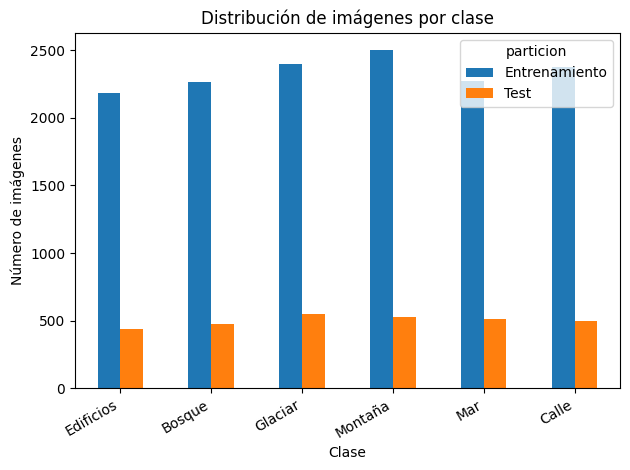

In [ ]:
# Creamos la tabla a partir del conjunto limpio.
tabla = pd.crosstab(
    datos_limpios['clase'],
    datos_limpios['particion']
).reindex(
    index=CLASES,
    columns=['train', 'test'],
    fill_value=0
)

# Calculamos el total de imágenes y los porcentajes por clase.
tabla['total'] = tabla[['train', 'test']].sum(axis=1)

tabla['porcentaje_total'] = (
    100 * tabla['total'] / tabla['total'].sum()
).round(2)

for parte in ['train', 'test']:
    tabla[f'porcentaje_{parte}'] = (
        100 * tabla[parte] / tabla[parte].sum()
    ).round(2)

display(tabla)

# Comparamos el tamaño de la clase mayoritaria y la minoritaria.
ratio = tabla['total'].max() / tabla['total'].min()

print('Imágenes del conjunto limpio:', len(datos_limpios))
print('Clases:', datos_limpios['clase'].nunique())
print('Relación mayoritaria/minoritaria:', round(ratio, 2))

# Representamos las imágenes de entrenamiento y test por clase.
ax = (
    tabla[['train', 'test']]
    .rename(
        index=NOMBRES,
        columns={
            'train': 'Entrenamiento',
            'test': 'Test'
        }
    )
    .plot.bar()
)

ax.set_title('Distribución de imágenes por clase')
ax.set_xlabel('Clase')
ax.set_ylabel('Número de imágenes')

plt.xticks(rotation=30, ha='right')
plt.tight_layout()

# Guardamos la gráfica en la carpeta de resultados.
plt.savefig(
    SALIDAS / 'distribucion_dataset_limpio.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()


## 1.7. Dimensiones originales y canales

Hemos analizado las dimensiones y los canales de color de las imágenes utilizando sus características originales, sin aplicar ningún redimensionamiento ni transformación.

Este análisis nos permite conocer la variedad de tamaños y formatos presentes en el conjunto de datos. La resolución y el tamaño de entrada que utilizaremos en las redes neuronales se determinarán en los apartados posteriores, teniendo en cuenta las características de los modelos y las necesidades del entrenamiento.

,ancho,alto,canales
count,17003.0,17003.00,17003.0
mean,150.0,149.91,3.0
std,0.0,1.99,0.0
min,150.0,72.00,3.0
25%,150.0,150.00,3.0
50%,150.0,150.00,3.0
75%,150.0,150.00,3.0
max,150.0,150.00,3.0


,ancho,alto,imagenes
31,150,150,16948
11,150,113,7
20,150,135,3
10,150,111,3
8,150,108,2
9,150,110,2
1,150,76,2
2,150,81,2
19,150,134,2
24,150,142,2


Imágenes analizadas: 17003
Resoluciones diferentes: 32


,modo,canales,formato,imagenes
0,RGB,3,JPEG,17003


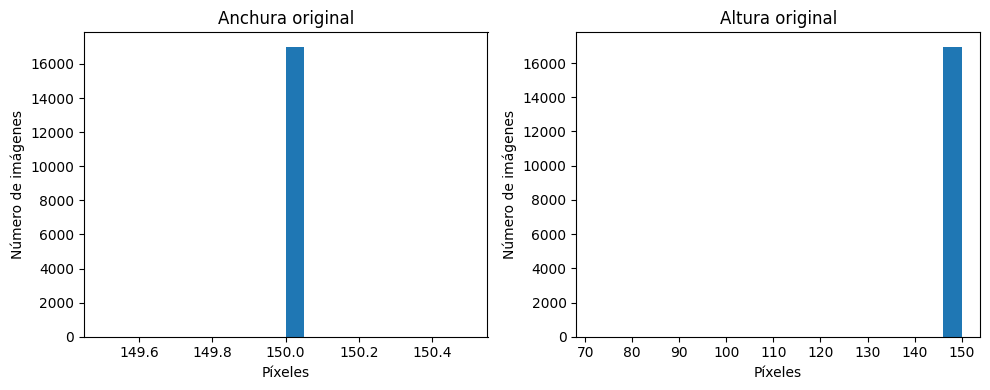

In [ ]:
# Contamos las imágenes de cada resolución y ordenamos por frecuencia.
resoluciones = (
    datos_limpios.groupby(['ancho', 'alto'])
    .size()
    .rename('imagenes')
    .reset_index()
    .sort_values('imagenes', ascending=False)
)

# Mostramos las estadísticas de tamaño y las resoluciones más frecuentes.
display(
    datos_limpios[
        ['ancho', 'alto', 'canales']
    ].describe().round(2)
)

display(resoluciones.head(20))

print('Imágenes analizadas:', len(datos_limpios))
print('Resoluciones diferentes:', len(resoluciones))

# Contamos las imágenes según su modo de color, canales y formato.
caracteristicas = (
    datos_limpios.groupby(['modo', 'canales', 'formato'])
    .size()
    .rename('imagenes')
    .reset_index()
    .sort_values('imagenes', ascending=False)
)

display(caracteristicas)

# Representamos la distribución de anchuras y alturas originales.
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

for eje, campo, titulo in zip(
    ejes,
    ['ancho', 'alto'],
    ['Anchura original', 'Altura original']
):
    eje.hist(datos_limpios[campo], bins=20)
    eje.set_title(titulo)
    eje.set_xlabel('Píxeles')
    eje.set_ylabel('Número de imágenes')

plt.tight_layout()

# Guardamos la gráfica en la carpeta de resultados.
plt.savefig(
    SALIDAS / 'dimensiones_dataset_limpio.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()


## 1.7. Keras Datasets

Hemos preparado los conjuntos de datos en un formato compatible con Keras para poder utilizarlos en las diferentes fases del proyecto: entrenamiento, validación y test.

De esta manera, disponemos de los datos organizados para alimentar los modelos de redes neuronales y evaluar posteriormente su rendimiento. Esta preparación nos permitirá trabajar con una estructura común en los distintos experimentos y facilitar la comparación de los resultados obtenidos.

In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomTranslation, RandomZoom, RandomContrast, RandomBrightness

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
RANDOM_SEED = 1234
EPOCHS = 300
class_names = CLASES
class_to_index = {clase: indice for indice, clase in enumerate(class_names)}

# Construimos las rutas exclusivamente desde el inventario depurado.
datos_modelado = datos_limpios.copy()
datos_modelado["ruta_completa"] = datos_modelado["ruta_relativa"].map(
    lambda ruta: str(DATOS / ruta)
)
datos_modelado["label"] = datos_modelado["clase"].map(class_to_index)

rutas_inexistentes = datos_modelado.loc[
    ~datos_modelado["ruta_completa"].map(lambda ruta: Path(ruta).is_file()),
    "ruta_completa"
]
if not rutas_inexistentes.empty:
    raise FileNotFoundError(
        f"Hay {len(rutas_inexistentes)} rutas del inventario limpio que no existen."
    )
if datos_modelado["label"].isna().any():
    raise ValueError("El inventario limpio contiene clases no incluidas en CLASES.")

# La validación se separa estratificadamente solo desde train; test queda intacto.
datos_train = datos_modelado[datos_modelado["particion"] == "train"].copy()
datos_test = datos_modelado[datos_modelado["particion"] == "test"].copy()
datos_train, datos_val = train_test_split(
    datos_train,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=datos_train["clase"]
)

def cargar_imagen(ruta, label):
    contenido = tf.io.read_file(ruta)
    imagen = tf.io.decode_image(
        contenido,
        channels=3,
        expand_animations=False
    )
    imagen = tf.image.resize(imagen, IMG_SIZE)
    imagen.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    return imagen, label

def crear_dataset(dataframe, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe["ruta_completa"].to_numpy(),
        dataframe["label"].to_numpy(dtype=np.int32)
    ))
    if shuffle:
        dataset = dataset.shuffle(
            len(dataframe),
            seed=RANDOM_SEED,
            reshuffle_each_iteration=True
        )
    return (
        dataset
        .map(cargar_imagen, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

train_ds = crear_dataset(datos_train, shuffle=True)
val_ds = crear_dataset(datos_val)
test_ds = crear_dataset(datos_test)

# Las imágenes permanecen en [0, 255]; los modelos normalizan según su arquitectura.
def preprocess_normalization(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Data augmentation únicamente en los lotes de entrenamiento.
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(factor=0.01, fill_mode="reflect"),
    RandomZoom(height_factor=0.2, width_factor=0.2, fill_mode="reflect"),
    RandomContrast(factor=0.5, value_range=(0, 255)),
    RandomBrightness(factor=0.05, value_range=(0, 255))
])

def preprocess_data_augmentation(image, label):
    image = data_augmentation(image, training=True)
    return image, label

train_ds_augmented = train_ds.map(
    preprocess_data_augmentation,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Imágenes limpias:", len(datos_modelado))
print("Train / validación / test:", len(datos_train), len(datos_val), len(datos_test))
print("Clases e índices:", class_to_index)
display(datos_modelado.groupby(["particion", "clase"]).size().unstack(fill_value=0))

Imágenes limpias: 17003
Train / validación / test: 11204 2802 2997
Clases e índices: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


clase,buildings,forest,glacier,mountain,sea,street
particion,,,,,,
test,436,474,552,525,510,500
train,2187,2269,2398,2504,2272,2376


### Verificar que el data augmentation produzca imágenes válidas

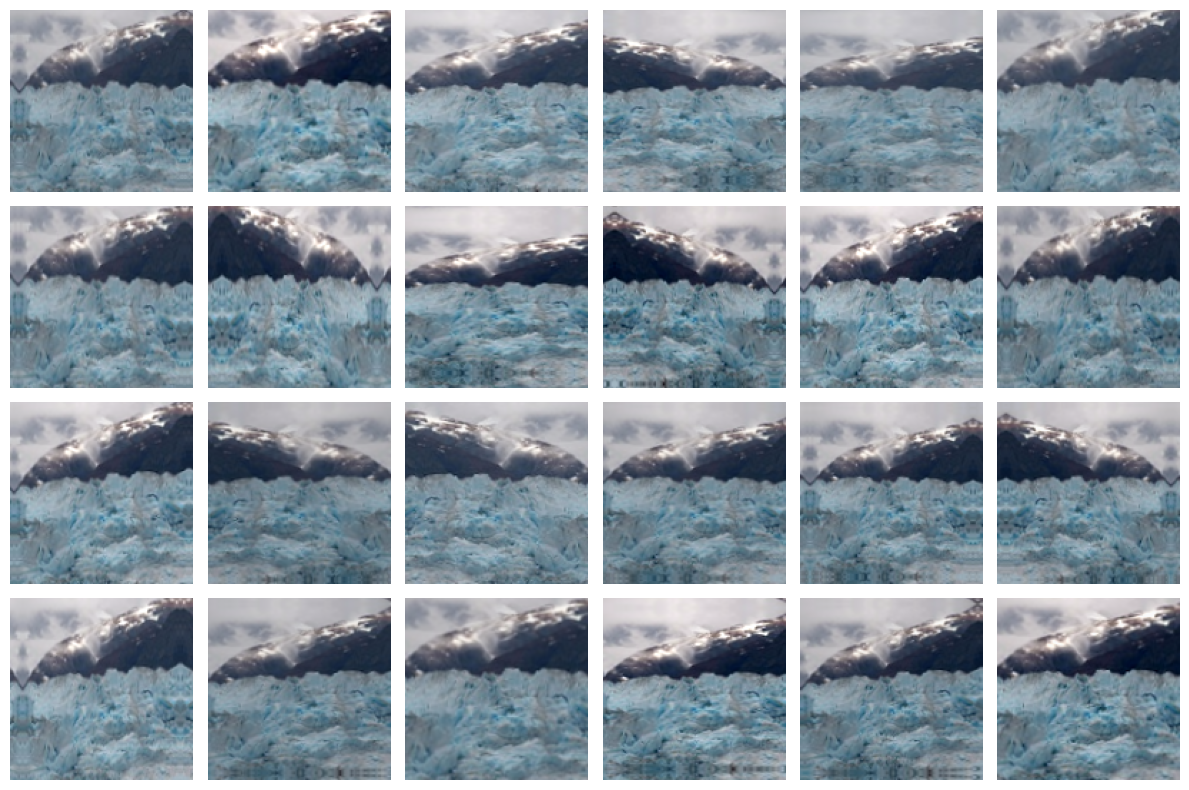

In [ ]:
fig, axes = plt.subplots(4, 6, figsize=(12, 8))

for image, label in train_ds:
    break
for i, ax in enumerate(axes.flat):
    augmented_image = data_augmentation(image, training=True )
    ax.imshow(augmented_image[0] / 255)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Verificar los datasets

train


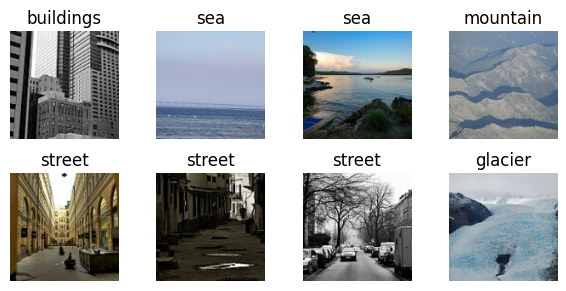

train - augmented


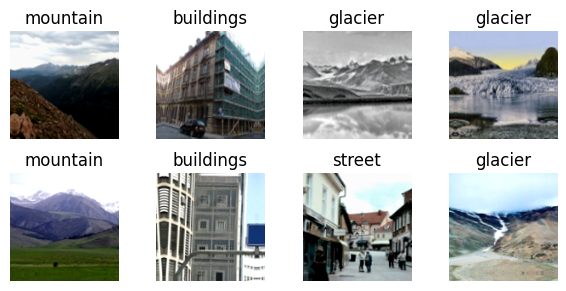

validation


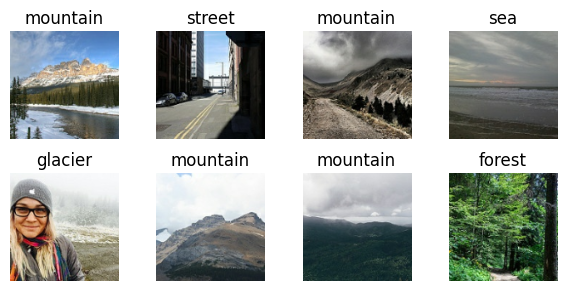

test


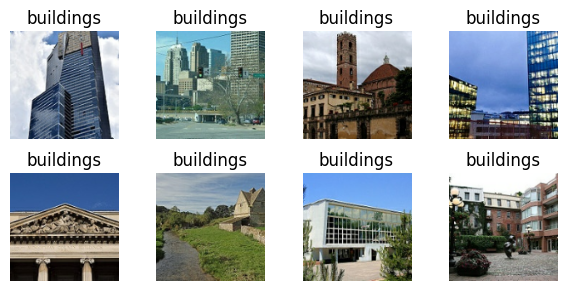

In [ ]:
import matplotlib.pyplot as plt

def plot_sample(dataset):
    fig, axes = plt.subplots(2, 4, figsize=(6, 3))
    images, labels = next(iter(dataset.take(1)))

    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i].numpy() / 255)
        label = class_names[labels[i].numpy()]
        ax.set_title(label)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

print('train')
plot_sample(train_ds)
print('train - augmented')
plot_sample(train_ds_augmented)
print('validation')
plot_sample(val_ds)
print('test')
plot_sample(test_ds)

## 2. Modelos de clasificación

In [ ]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense, GlobalAveragePooling2D, BatchNormalization, Dropout, ReLU, Add
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

MODELS = Path.cwd() / 'models' / 'datos_limpios'
MODELS.mkdir(parents=True, exist_ok=True)


## 2.1 Modelo Base

Clase base donde se implementarán los métodos que se reutilizarán en el resto de las implementaciones
* build: Crea el Model
* train: Entrena el modelo
* load: Recupera los pesos e imagen de resultados
* save: Almacena los pesos e imagen de resultados
* plot_history: Crea la imagen del entrenamiento
* show_history: Muestra la imagen del entrenamiento
* evaluate: Evalua el modelo con el dataset de test
* display_confusion_matrix: Construye la matriz de confusión
* print_classification_report: Imprime las métricas



In [ ]:
class base_model:
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds):
        self.name = name
        self.epochs = epochs
        self.batch_size = batch_size
        self.train_ds = train_ds
        self.val_ds = val_ds
        self.test_ds = test_ds
        self.model = None

    def build(self):
        raise Exception("Implementar build")

    def train(self):
        # callback para que pare si no mejora en 20 epochs
        early_stopping = EarlyStopping(monitor="val_accuracy", patience=20, mode="max", restore_best_weights=True)
        # callback para que reduzca el learningrate si no mejora en 10 epochs
        reduce_lr = ReduceLROnPlateau(monitor="val_accuracy", mode="max", factor=0.1, patience=10, min_delta=1e-6, cooldown=1, min_lr=1e-10, verbose=0)
        # entrenar
        history = self.model.fit(x = self.train_ds,
                                 validation_data=self.val_ds,
                                 epochs=self.epochs,
                                 batch_size = self.batch_size,
                                 callbacks=[early_stopping, reduce_lr])
        # almacenar el mejor modelo (solo pesos)
        self.model.save_weights(MODELS / f"{self.name}.weights.h5")
        # dibujar metricas
        self.plot_history(history)

    def load(self):
        # verificar que esté construido
        if self.model is None:
            self.build()
        pesos = MODELS / f"{self.name}.weights.h5"
        if os.path.exists(pesos):
            # cargar los pesos
            self.model.load_weights(pesos)
            return True
        return False

    def plot_history(self, H):
        epochs = len(H.history["loss"])
        plt.style.use("ggplot")
        plt.figure()
        plt.plot(np.arange(0, epochs), H.history["loss"], label="train_loss")
        plt.plot(np.arange(0, epochs), H.history["val_loss"], label="val_loss")
        plt.plot(np.arange(0, epochs), H.history["accuracy"], label="train_acc")
        plt.plot(np.arange(0, epochs), H.history["val_accuracy"], label="val_acc")
        plt.title("Training Loss and Accuracy")
        plt.xlabel("Epoch #")
        plt.ylabel("Loss/Accuracy")
        plt.legend()
        plt.savefig(MODELS / f"{self.name}.png")
        plt.close()

    def show_history(self):
        # cargar y dibujar la imagen
        image = Image.open(MODELS / f"{self.name}.png")
        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.axis('off')
        plt.show()

    def evaluate(self):
        y_true = np.concatenate([labels.numpy() for images, labels in self.test_ds])
        y_pred_prob = self.model.predict(self.test_ds)
        y_pred = np.argmax(y_pred_prob, axis=1)
        return y_true, y_pred

    def display_confusion_matrix(self, y_true, y_pred):
        cm = confusion_matrix(y_true, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
        fig, ax = plt.subplots(figsize=(6, 6))
        disp.plot(
            ax=ax,
            cmap='Blues',
            values_format='d',
            colorbar=False
        )
        plt.title(f"Matriz de Confusión - {self.name}")
        plt.tight_layout()
        plt.show()

    def print_classification_report(self, y_true, y_pred):
        print(classification_report(
            y_true,
            y_pred,
            target_names=class_names,
            digits=4
        ))


## 2.2 Modelo CNN Simple

Diseño de una red CNN simple, sin conexiones residuales, sin regularización.

Las imagenes serán de 128 x 128 x 3 canales (RGB) y las normalizaremos entre [0,1]

Será nuestro modelo más simple del cual iremos evolucionando y probando distintas alternativas.

* Input (B, 128, 128, 3)
* Conv2D 32 features con kernel 3x3, activación relu, sin padding
* MaxPooling2D (2x2)
* Conv2D 64 features con kernel 3x3, activación relu, sin padding
* MaxPooling2D (2x2)
* Conv2D 128 features con kernel 3x3, activación relu, sin padding
* GlobalAveragePooling2D (2x2)
* Capa Dense 64 neuronas, activación relu
* Capa Dense 6 neuronas (una por cada clase) y activación softmax

In [ ]:
class simple_CNN_model(base_model):
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds):
        # adecuar el dataset de test, ya que utilizaremos normalización [0,1]
        # también aplicaremos shuffle así incorporamos variabilidad en el entrenamiento
        train_ds = (
            train_ds
            .map(preprocess_normalization, num_parallel_calls=tf.data.AUTOTUNE)
            .shuffle(batch_size * 5)
            .prefetch(tf.data.AUTOTUNE)
        )
        # adecuar el dataset de test, ya que utilizaremos normalización [0,1]
        val_ds = (
            val_ds
            .map(preprocess_normalization, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )
        # adecuar el dataset de test, ya que utilizaremos normalización [0,1]
        test_ds = (
            test_ds
            .map(preprocess_normalization, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )
        # inicial clase base
        super(simple_CNN_model, self).__init__(name = name,
                                               epochs = epochs,
                                               batch_size = batch_size,
                                               train_ds = train_ds,
                                               val_ds = val_ds,
                                               test_ds = test_ds)

    def build(self):
        inputs = Input(shape=(IMG_SIZE + (3,))) # 128x128x3

        # CNN
        x = Conv2D(32, 3, activation='relu')(inputs) # 126x126x32
        x = MaxPooling2D()(x) # 63x63x32

        x = Conv2D(64, 3, activation='relu')(x) # Bx61x61x64
        x = MaxPooling2D()(x) # 30x30x64

        x = Conv2D(128, 3, activation='relu')(x) # 28x28x128
        x = GlobalAveragePooling2D()(x) # 28

        x = Dense(64, activation='relu')(x) # 64

        # ultima capa clasificación, activación softmax para la probabilidad de cada clase
        outputs = Dense(len(class_names), activation='softmax')(x) # 6

        # modelo
        self.model = tf.keras.Model(inputs, outputs, name=self.name)
        self.model.compile(optimizer=Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        self.model.summary()



In [ ]:
# version simple CNN
simple_CNN = simple_CNN_model(name = "simple_CNN",
                              epochs=EPOCHS,
                              batch_size=BATCH_SIZE,
                              train_ds = train_ds,
                              val_ds = val_ds,
                              test_ds = test_ds
                            )
simple_CNN.build()

Model: "simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 34s 58ms/step - accuracy: 0.4460 - loss: 1.2834 - val_accuracy: 0.5004 - val_loss: 1.1808 - learning_rate: 0.0010
Epoch 2/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.5788 - loss: 1.0166 - val_accuracy: 0.6538 - val_loss: 0.9523 - learning_rate: 0.0010
Epoch 3/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.6361 - loss: 0.9133 - val_accuracy: 0.6713 - val_loss: 0.8611 - learning_rate: 0.0010
Epoch 4/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.6773 - loss: 0.8345 - val_accuracy: 0.7034 - val_loss: 0.7844 - learning_rate: 0.0010
Epoch 5/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.7085 - loss: 0.7583 - val_accuracy: 0.6702 - val_loss: 0.8460 - learning_rate: 0.0010
Epoch 6/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.7393 - loss: 0.6991 - val_accuracy: 0.7598 - val_loss: 0.6850 - learning_rate: 0.0010
Epoch 7/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.747

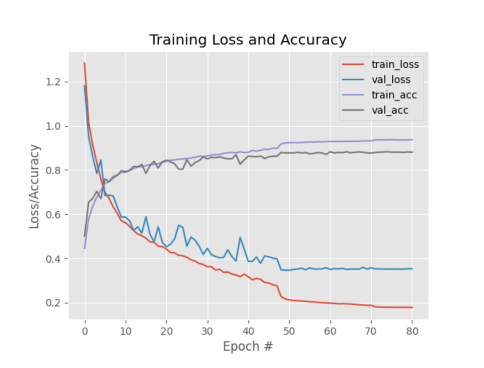

In [ ]:
# Intentar cargar los pesos anteriores, sino entrenar
if not simple_CNN.load():
    # No hay pesos almacenados, entonces entrenar
    simple_CNN.train()
# mostrar la imagen de la historia del entrenamiento
simple_CNN.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step


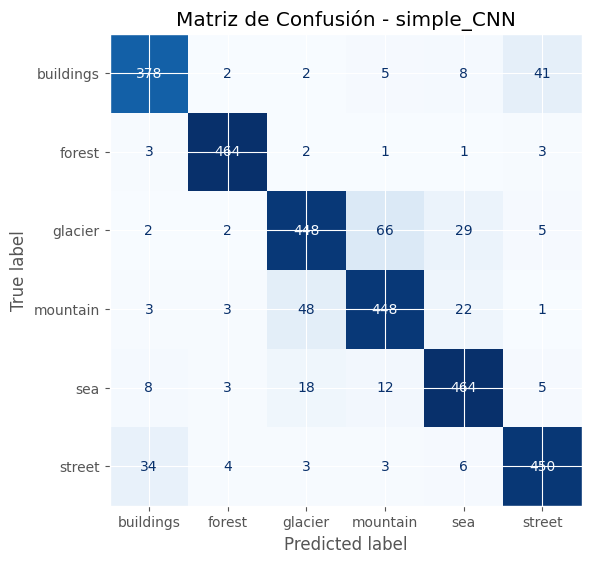

              precision    recall  f1-score   support

   buildings     0.8832    0.8670    0.8750       436
      forest     0.9707    0.9789    0.9748       474
     glacier     0.8599    0.8116    0.8350       552
    mountain     0.8374    0.8533    0.8453       525
         sea     0.8755    0.9098    0.8923       510
      street     0.8911    0.9000    0.8955       500

    accuracy                         0.8849      2997
   macro avg     0.8863    0.8868    0.8863      2997
weighted avg     0.8847    0.8849    0.8846      2997



In [ ]:
# Evaluar
y_true, y_pred = simple_CNN.evaluate()
# Matriz de confusion
simple_CNN.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
simple_CNN.print_classification_report(y_true, y_pred)

## 2.3 Modelo CNN Simple: Data Agumentation

Utilizaremos el mismo modelo anterior, solamente cambiaremos la inicialización para que entrenare con el dataset que tiene aplicado data augmentation.

In [ ]:
# version simple CNN con Data Augmentation
simple_CNN_aug = simple_CNN_model(name = "simple_CNN_augmented",
                                  epochs=EPOCHS,
                                  batch_size=BATCH_SIZE,
                                  train_ds = train_ds_augmented,
                                  val_ds = val_ds,
                                  test_ds = test_ds)
simple_CNN_aug.build()

Model: "simple_CNN_augmented"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 48s 80ms/step - accuracy: 0.4464 - loss: 1.3038 - val_accuracy: 0.5514 - val_loss: 1.2048 - learning_rate: 0.0010
Epoch 2/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 42s 71ms/step - accuracy: 0.5683 - loss: 1.0593 - val_accuracy: 0.6028 - val_loss: 1.0413 - learning_rate: 0.0010
Epoch 3/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 72ms/step - accuracy: 0.6091 - loss: 0.9914 - val_accuracy: 0.6253 - val_loss: 0.9377 - learning_rate: 0.0010
Epoch 4/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 73ms/step - accuracy: 0.6377 - loss: 0.9293 - val_accuracy: 0.6892 - val_loss: 0.8701 - learning_rate: 0.0010
Epoch 5/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 42s 73ms/step - accuracy: 0.6740 - loss: 0.8617 - val_accuracy: 0.7213 - val_loss: 0.7798 - learning_rate: 0.0010
Epoch 6/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 73ms/step - accuracy: 0.6882 - loss: 0.8182 - val_accuracy: 0.7270 - val_loss: 0.7725 - learning_rate: 0.0010
Epoch 7/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 42s 72ms/step - accuracy: 0.7

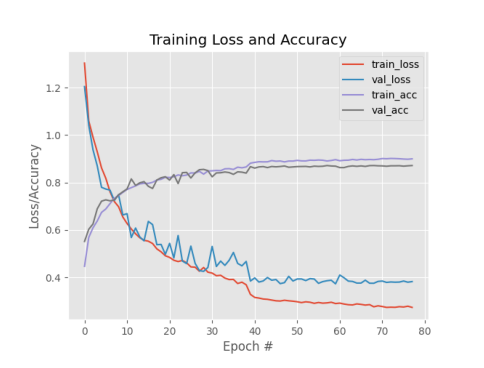

In [ ]:
# Intentar cargar los pesos anteriores, sino entrenar
if not simple_CNN_aug.load():
    # No hay pesos almacenados, entonces entrenar
    simple_CNN_aug.train()
# mostrar la imagen de la historia del entrenamiento
simple_CNN_aug.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step


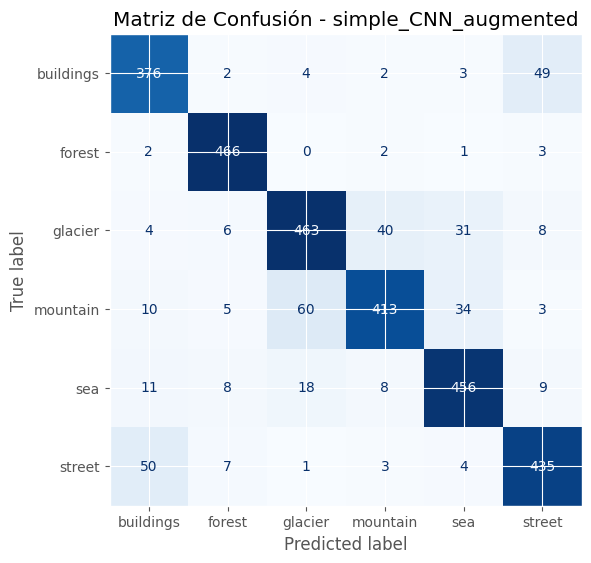

              precision    recall  f1-score   support

   buildings     0.8300    0.8624    0.8459       436
      forest     0.9433    0.9831    0.9628       474
     glacier     0.8480    0.8388    0.8434       552
    mountain     0.8825    0.7867    0.8318       525
         sea     0.8620    0.8941    0.8778       510
      street     0.8580    0.8700    0.8640       500

    accuracy                         0.8705      2997
   macro avg     0.8706    0.8725    0.8709      2997
weighted avg     0.8705    0.8705    0.8699      2997



In [ ]:
# Evaluar
y_true, y_pred = simple_CNN_aug.evaluate()
# Matriz de confusion
simple_CNN_aug.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
simple_CNN_aug.print_classification_report(y_true, y_pred)

## 2.4 Modelo CNN Simple v2: Regularización

Evolución del modelo CNN Simple utilizando regularización:

* BatchNormalization: luego de cada capa Conv2D aplicaremos Batch Normalization para estabilizar el entrenamiento
* Dropout: aplicaremos dropout para evitar sobreajuste.

Cada bloque Conv2D + MaxPooling2D queda compuesto por:
* Conv2D (sin activación)
* BatchNormalization
* ReLU (aplicamos activación relu)
* MaxPooling2D


In [ ]:
class simple_CNNv2_model(simple_CNN_model):
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds, dropout_rate = 0.1):
        # inicial clase base
        super(simple_CNN_model, self).__init__(name = name,
                                               epochs = epochs,
                                               batch_size = batch_size,
                                               train_ds = train_ds,
                                               val_ds = val_ds,
                                               test_ds = test_ds)
        self.dropout_rate = dropout_rate

    def build(self):
        inputs = Input(shape=(IMG_SIZE + (3,))) # 128x128x3

        # CNN
        x = Conv2D(32, 3)(inputs) # 126x126x32
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = MaxPooling2D()(x) # 63x63x32

        x = Conv2D(64, 3)(x) # 61x61x64
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = MaxPooling2D()(x) # 30x30x64

        x = Conv2D(128, 3)(x) # 28x28x128
        x = BatchNormalization()(x)
        x = ReLU()(x)
        x = GlobalAveragePooling2D()(x) # 128
        x = Dropout(self.dropout_rate)(x)

        x = Dense(64, activation='relu')(x) # 64
        x = Dropout(self.dropout_rate)(x)

        outputs = Dense(len(class_names), activation='softmax')(x) # 6
        self.model = tf.keras.Model(inputs, outputs, name=self.name)
        self.model.compile(optimizer=Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        self.model.summary()

In [ ]:
# version simple CNN v2 con regularización
simple_CNNv2 = simple_CNNv2_model(name = "simple_CNNv2",
                                  epochs=EPOCHS,
                                  batch_size=BATCH_SIZE,
                                  train_ds = train_ds,
                                  val_ds = val_ds,
                                  test_ds = test_ds)
simple_CNNv2.build()

Model: "simple_CNNv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,790 (401.52 KB)

 Trainable params: 102,342 (399.77 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 52ms/step - accuracy: 0.6205 - loss: 0.9562 - val_accuracy: 0.5621 - val_loss: 1.2696 - learning_rate: 0.0010
Epoch 2/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.7174 - loss: 0.7371 - val_accuracy: 0.3822 - val_loss: 1.8167 - learning_rate: 0.0010
Epoch 3/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.7458 - loss: 0.6721 - val_accuracy: 0.5153 - val_loss: 1.3081 - learning_rate: 0.0010
Epoch 4/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.7652 - loss: 0.6329 - val_accuracy: 0.7455 - val_loss: 0.6966 - learning_rate: 0.0010
Epoch 5/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.7803 - loss: 0.5864 - val_accuracy: 0.7830 - val_loss: 0.5972 - learning_rate: 0.0010
Epoch 6/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.7875 - loss: 0.5631 - val_accuracy: 0.7677 - val_loss: 0.6393 - learning_rate: 0.0010
Epoch 7/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.7959 -

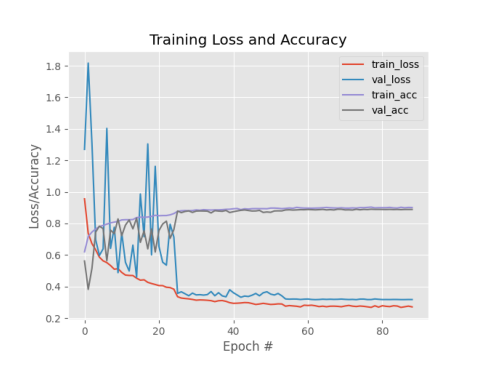

In [ ]:
# Intentar cargar los pesos anteriores, sino entrenar
if not simple_CNNv2.load():
    # No hay pesos almacenados, entonces entrenar
    simple_CNNv2.train()
# mostrar la imagen de la historia del entrenamiento
simple_CNNv2.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step


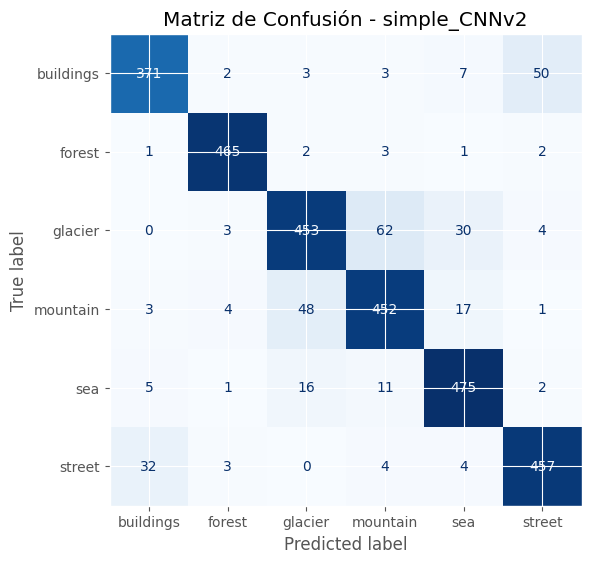

              precision    recall  f1-score   support

   buildings     0.9005    0.8509    0.8750       436
      forest     0.9728    0.9810    0.9769       474
     glacier     0.8678    0.8207    0.8436       552
    mountain     0.8449    0.8610    0.8528       525
         sea     0.8895    0.9314    0.9100       510
      street     0.8857    0.9140    0.8996       500

    accuracy                         0.8919      2997
   macro avg     0.8935    0.8932    0.8930      2997
weighted avg     0.8918    0.8919    0.8915      2997



In [ ]:
# Evaluar
y_true, y_pred = simple_CNNv2.evaluate()
# Matriz de confusion
simple_CNNv2.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
simple_CNNv2.print_classification_report(y_true, y_pred)

## 2.5 Modelo CNN con conexiones residuales

Modelo con mayor profundidad y uso de conexiones residuales. Esto permite tener un modelo que logre ver detalles que los modelos simples no llegan a capturar y el uso de conexiones residuales permite un entrenamiento más estable en redes más produndas o complejas.

Se hace una primer proyección y luego tres bloques de conexión residual.

Cada bloque residual está compuesto por dos capas de convolusión y una capa adicional para la conexión residual si es necesario adaptar los features o dimesión porque se usó strides distinto de 1


In [ ]:
def residual_block(x, filters, kernel_size=3, stride=1,l2_reg=1e-4, dropout_rate=0.0):
    shortcut = x

    # Primera convolución
    x = Conv2D(filters, kernel_size, strides=stride, padding='same', use_bias=False, kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)

    # Segunda convolución
    x = Conv2D(filters, kernel_size, strides=1, padding='same', use_bias=False, kernel_regularizer=l2(l2_reg))(x)
    x = BatchNormalization()(x)

    # Ajustar dimensiones de shortcut si es necesario, ya sea cambia el stride o no coinciden los features con los nuevos filtros
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = Conv2D(filters, 1, strides=stride, padding='same', use_bias=False,kernel_regularizer=l2(l2_reg))(shortcut)
        shortcut = BatchNormalization()(shortcut)

    # Conexión residual
    x = Add()([x, shortcut])
    x = ReLU()(x)

    if dropout_rate > 0:
        x = Dropout(dropout_rate)(x)

    return x


class residual_CNN_model(simple_CNN_model):
    def __init__(self, name, epochs, batch_size, train_ds, val_ds, test_ds):
        # inicial clase base
        super(simple_CNN_model, self).__init__(name = name,
                                               epochs = epochs,
                                               batch_size = batch_size,
                                               train_ds = train_ds,
                                               val_ds = val_ds,
                                               test_ds = test_ds)

    def build(self):
        # tensor de entrada
        inputs = Input(shape=(IMG_SIZE + (3,))) # 128x128x3

        # primer proyeccion
        x = Conv2D(32, 3, padding='same', use_bias=False)(inputs) # 128x128x32
        x = BatchNormalization()(x)
        x = ReLU()(x)

        # Bloque residual 1
        x = residual_block(x, 32, dropout_rate=0.10) # 128x128x32

        # Bloque residual 2
        x = residual_block(x, 64, stride=2, dropout_rate=0.15) # 64x64x64

        # Bloque residual 3
        x = residual_block(x, 128, stride=2, dropout_rate=0.20) # 32x32x128

        x = GlobalAveragePooling2D()(x) # 128
        x = Dropout(0.1)(x)
        x = Dense(64, activation='relu', kernel_regularizer=l2(1e-6))(x) # 64
        x = Dropout(0.1)(x)

        outputs = Dense(len(class_names), activation='softmax', kernel_regularizer=l2(1e-6))(x) # 6

        self.model = tf.keras.Model(inputs, outputs, name=self.name)
        self.model.compile(optimizer=Adam(learning_rate=1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        self.model.summary()

In [ ]:
# version CNN residual
residual_CNN = residual_CNN_model(name = "residual_CNN",
                                  epochs=EPOCHS,
                                  batch_size=BATCH_SIZE,
                                  train_ds = train_ds,
                                  val_ds = val_ds,
                                  test_ds = test_ds)
residual_CNN.build()

Model: "residual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │        864 │ input_layer_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 128, 128,  │      9,216 │ re_lu_3[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_4 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 128, 128,  │      9,216 │ re_lu_4[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │ re_lu_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_5 (ReLU)      │ (None, 128, 128,  │          0 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128, 128,  │          0 │ re_lu_5[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 64,    │     18,432 │ dropout_2[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_6 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 64, 64,    │     36,864 │ re_lu_6[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 64, 64,    │      2,048 │ dropout_2[0][0] 

 Total params: 317,350 (1.21 MB)

 Trainable params: 316,006 (1.21 MB)

 Non-trainable params: 1,344 (5.25 KB)

Epoch 1/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 81s 155ms/step - accuracy: 0.5967 - loss: 1.0460 - val_accuracy: 0.7045 - val_loss: 0.8145 - learning_rate: 0.0010
Epoch 2/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.7125 - loss: 0.8026 - val_accuracy: 0.5507 - val_loss: 1.6748 - learning_rate: 0.0010
Epoch 3/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 81ms/step - accuracy: 0.7558 - loss: 0.7024 - val_accuracy: 0.6085 - val_loss: 1.1755 - learning_rate: 0.0010
Epoch 4/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 29s 81ms/step - accuracy: 0.7870 - loss: 0.6340 - val_accuracy: 0.7302 - val_loss: 0.8133 - learning_rate: 0.0010
Epoch 5/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.8019 - loss: 0.5923 - val_accuracy: 0.4847 - val_loss: 1.5677 - learning_rate: 0.0010
Epoch 6/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 79ms/step - accuracy: 0.8112 - loss: 0.5634 - val_accuracy: 0.7855 - val_loss: 0.6478 - learning_rate: 0.0010
Epoch 7/300
351/351 ━━━━━━━━━━━━━━━━━━━━ 41s 81ms/step - accuracy: 0.

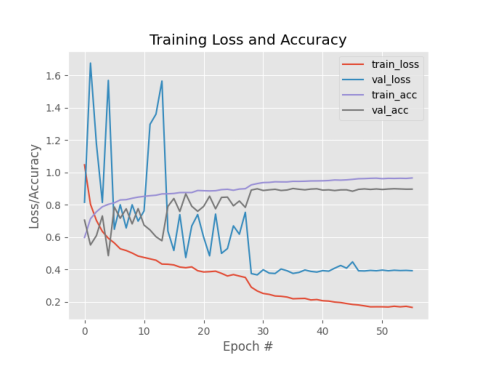

In [ ]:
# Intentar cargar los pesos anteriores, sino entrenar
if not residual_CNN.load():
    # No hay pesos almacenados, entonces entrenar
    residual_CNN.train()
# mostrar la imagen de la historia del entrenamiento
residual_CNN.show_history()

94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 76ms/step


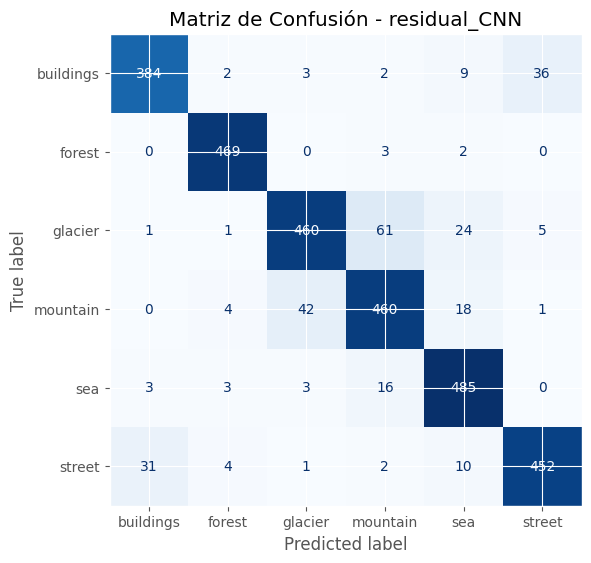

              precision    recall  f1-score   support

   buildings     0.9165    0.8807    0.8982       436
      forest     0.9710    0.9895    0.9801       474
     glacier     0.9037    0.8333    0.8671       552
    mountain     0.8456    0.8762    0.8606       525
         sea     0.8850    0.9510    0.9168       510
      street     0.9150    0.9040    0.9095       500

    accuracy                         0.9042      2997
   macro avg     0.9061    0.9058    0.9054      2997
weighted avg     0.9047    0.9042    0.9039      2997



In [ ]:
# Evaluar
y_true, y_pred = residual_CNN.evaluate()
# Matriz de confusion
residual_CNN.display_confusion_matrix(y_true, y_pred)
# Informe de clasificacion
residual_CNN.print_classification_report(y_true, y_pred)

## 3.Transfer Learning con MobileNetV2

En este apartado se utiliza **MobileNetV2**, una red neuronal convolucional preentrenada. El entrenamiento se divide en dos fases:

3.1 **Feature extraction:** se congelan los pesos de MobileNetV2 y se entrenan únicamente las nuevas capas de clasificación.

3.2 **Fine-tuning:** se descongelan las últimas capas de la red y se entrenan con una tasa de aprendizaje menor para adaptar mejor el modelo a nuestro problema.

### 3.1. Feature extraction

En esta primera fase hemos utilizado MobileNetV2, una red convolucional preentrenada con ImageNet, como extractor de características. Para ello, hemos eliminado su capa de clasificación original y mantenido congelados los pesos de la red preentrenada, de manera que únicamente se entrenen las nuevas capas de clasificación.

Hemos añadido una capa GlobalAveragePooling2D, una capa Dropout de 0,2 para reducir el riesgo de sobreajuste y una capa final Dense con activación softmax para clasificar las imágenes en las seis categorías del conjunto de datos.

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

class MobileNetV2_model(base_model):

    def __init__(self, name, epochs, batch_size,
                 train_ds, val_ds, test_ds):

        # Los datasets originales contienen imágenes en [0, 255].
        # MobileNetV2 necesita valores en [-1, 1].
        train_ds = (
            train_ds
            .map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y),
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )

        val_ds = (
            val_ds
            .map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y),
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )

        test_ds = (
            test_ds
            .map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y),
                 num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE)
        )

        super().__init__(
            name=name,
            epochs=epochs,
            batch_size=batch_size,
            train_ds=train_ds,
            val_ds=val_ds,
            test_ds=test_ds
        )

        self.base_network = None

    def build(self):

        # Red preentrenada con ImageNet
        self.base_network = MobileNetV2(
            weights="imagenet",
            include_top=False,
            input_shape=IMG_SIZE + (3,)
        )

        # Congelamos la red preentrenada
        self.base_network.trainable = False

        inputs = Input(shape=IMG_SIZE + (3,))

        # Extracción de características
        x = self.base_network(inputs, training=False)

        # Nuevas capas de clasificación
        x = GlobalAveragePooling2D()(x)
        x = Dropout(0.2)(x)
        outputs = Dense(
            len(class_names),
            activation="softmax"
        )(x)

        self.model = tf.keras.Model(
            inputs,
            outputs,
            name=self.name
        )

        self.model.compile(
            optimizer=Adam(learning_rate=1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        self.model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 59s 108ms/step - accuracy: 0.8617 - loss: 0.3820 - val_accuracy: 0.9026 - val_loss: 0.2662 - learning_rate: 0.0010
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9138 - loss: 0.2397 - val_accuracy: 0.9136 - val_loss: 0.2523 - learning_rate: 0.0010
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.9236 - loss: 0.2129 - val_accuracy: 0.9111 - val_loss: 0.2431 - learning_rate: 0.0010
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.9277 - loss: 0.1943 - val_accuracy: 0.9143 - val_loss: 0.2472 - learning_rate: 0.0010
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9310 - loss: 0.1843 - val_accuracy: 0.9097 - val_loss: 0.2525 - learning_rate: 0.0010
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9338 - loss: 0.1755 - val_accuracy: 0.9029 - val_loss: 0.2659 - learning_rate: 0.0010
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9351 - loss:

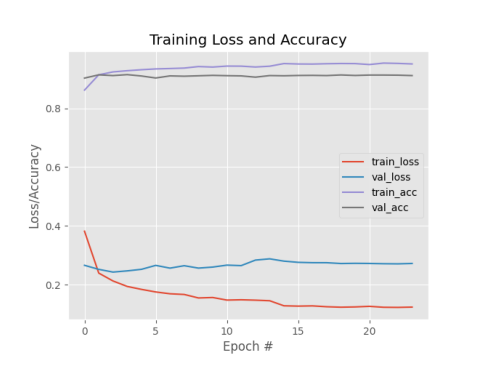

In [ ]:
# Crear el modelo MobileNetV2

mobileNetV2 = MobileNetV2_model(
    name="MobileNetV2",
    epochs=30,
    batch_size=BATCH_SIZE,
    train_ds=train_ds,
    val_ds=val_ds,
    test_ds=test_ds
)

mobileNetV2.build()

# Entrenar o recuperar pesos guardados
if not mobileNetV2.load():
    mobileNetV2.train()

# Mostrar evolución del entrenamiento
if (MODELS / "MobileNetV2.png").exists():
    mobileNetV2.show_history()


### 3.2 Fine-tuning

En esta segunda fase hemos realizado un ajuste fino (fine-tuning) de MobileNetV2 para adaptar mejor la red preentrenada a las características de nuestro conjunto de imágenes.

Para ello, hemos descongelado las últimas 30 capas de MobileNetV2, manteniendo congeladas las capas anteriores y todas las capas BatchNormalization. De esta forma, podemos ajustar parte de los pesos preentrenados sin modificar completamente las características aprendidas previamente.

Además, hemos reducido la tasa de aprendizaje a 1e-5 para ajustar los pesos y evitar cambios demasiado bruscos en los parámetros preentrenados.

Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 1,518,406 (5.79 MB)

 Non-trainable params: 747,264 (2.85 MB)

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 32s 57ms/step - accuracy: 0.9342 - loss: 0.1736 - val_accuracy: 0.9193 - val_loss: 0.2358 - learning_rate: 1.0000e-05
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9486 - loss: 0.1390 - val_accuracy: 0.9179 - val_loss: 0.2481 - learning_rate: 1.0000e-05
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9562 - loss: 0.1183 - val_accuracy: 0.9115 - val_loss: 0.2436 - learning_rate: 1.0000e-05
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9669 - loss: 0.0971 - val_accuracy: 0.9208 - val_loss: 0.2409 - learning_rate: 1.0000e-05
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9695 - loss: 0.0852 - val_accuracy: 0.9240 - val_loss: 0.2461 - learning_rate: 1.0000e-05
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.9758 - loss: 0.0689 - val_accuracy: 0.9183 - val_loss: 0.2556 - learning_rate: 1.0000e-05
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step -

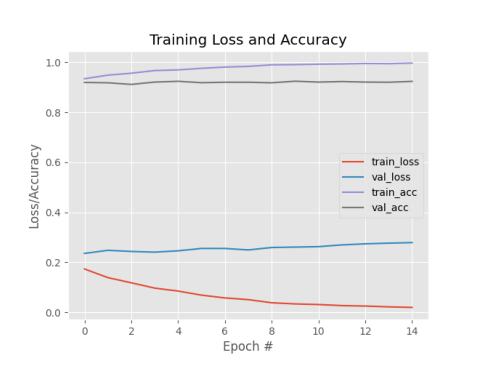

In [ ]:
#Fine-tuning de MobileNetV2

fine_tuning_weights = MODELS / "MobileNetV2_finetuned.weights.h5"
fine_tuning_plot = MODELS / "MobileNetV2_finetuned.png"

if fine_tuning_weights.exists():

    # Recuperamos el modelo ya ajustado
    mobileNetV2.base_network.trainable = True

    for layer in mobileNetV2.base_network.layers[:-30]:
        layer.trainable = False

    # Mantenemos congeladas las BatchNormalization
    for layer in mobileNetV2.base_network.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    mobileNetV2.model.load_weights(fine_tuning_weights)
    print("Pesos del fine-tuning recuperados.")

else:

    # Descongelamos únicamente las últimas 30 capas
    mobileNetV2.base_network.trainable = True

    for layer in mobileNetV2.base_network.layers[:-30]:
        layer.trainable = False

    # Las BatchNormalization permanecen congeladas
    for layer in mobileNetV2.base_network.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    # Learning rate menor para no alterar bruscamente
    # los pesos preentrenados
    mobileNetV2.model.compile(
        optimizer=Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    mobileNetV2.model.summary()

    # Entrenamiento con parada anticipada
    history_finetuning = mobileNetV2.model.fit(
        mobileNetV2.train_ds,
        validation_data=mobileNetV2.val_ds,
        epochs=20,
        callbacks=[
            EarlyStopping(
                monitor="val_accuracy",
                patience=5,
                mode="max",
                restore_best_weights=True
            ),
            ReduceLROnPlateau(
                monitor="val_accuracy",
                factor=0.5,
                patience=3,
                mode="max",
                min_lr=1e-7
            )
        ]
    )

    # Guardamos pesos y gráfica por separado
    mobileNetV2.model.save_weights(fine_tuning_weights)

    mobileNetV2.plot_history(history_finetuning)

    # Guardamos la gráfica con otro nombre
    import shutil
    shutil.copyfile(
        MODELS / "MobileNetV2.png",
        fine_tuning_plot
    )

# Mostrar gráfica del fine-tuning si existe
if fine_tuning_plot.exists():
    from PIL import Image
    plt.figure(figsize=(6, 6))
    plt.imshow(Image.open(fine_tuning_plot))
    plt.axis("off")
    plt.show()


### 3.3 Evaluación con fine-tuning y resultados

Una vez finalizado el *fine-tuning*, hemos evaluado MobileNetV2 utilizando el conjunto de test, formado por 2.997 imágenes distribuidas en seis categorías.

Para analizar el rendimiento del modelo hemos calculado la pérdida (*loss*) y la exactitud (*accuracy*), además de las métricas de precisión, recall y F1-score para cada categoría. También hemos generado una matriz de confusión para observar los aciertos y errores de clasificación.

En este apartado analizamos únicamente los resultados obtenidos con MobileNetV2. La comparación con los demás modelos del proyecto se realiza en la sección 5.


94/94 ━━━━━━━━━━━━━━━━━━━━ 16s 171ms/step - accuracy: 0.9256 - loss: 0.2284
Test Loss: 0.2284
Test Accuracy: 0.9256
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step


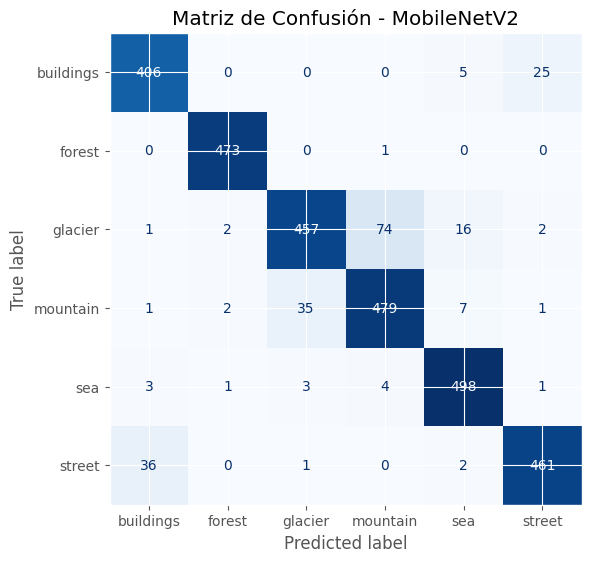

              precision    recall  f1-score   support

   buildings     0.9083    0.9312    0.9196       436
      forest     0.9895    0.9979    0.9937       474
     glacier     0.9214    0.8279    0.8721       552
    mountain     0.8584    0.9124    0.8846       525
         sea     0.9432    0.9765    0.9595       510
      street     0.9408    0.9220    0.9313       500

    accuracy                         0.9256      2997
   macro avg     0.9269    0.9280    0.9268      2997
weighted avg     0.9262    0.9256    0.9252      2997



In [ ]:

# Evaluación final de MobileNetV2

loss, accuracy = mobileNetV2.model.evaluate(
    mobileNetV2.test_ds,
    verbose=1
)

print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

# Predicciones
y_true, y_pred = mobileNetV2.evaluate()

# Matriz de confusión
mobileNetV2.display_confusion_matrix(y_true, y_pred)

# Informe de clasificación
mobileNetV2.print_classification_report(y_true, y_pred)


##3.4 Análisis de las curvas de aprendizaje y sobreajuste

Tras realizar el fine-tuning, MobileNetV2 ha alcanzado una exactitud del 92,56 % y una pérdida de 0,2284 sobre el conjunto de test. Además, ha obtenido una precisión macro del 92,69 %, un recall macro del 92,80 % y un F1-score macro del 92,68 %. Estos resultados muestran un buen rendimiento general del modelo en la clasificación de las seis categorías.

Al analizar los resultados por categoría, observamos que forest presenta el mejor comportamiento, con un F1-score del 99,37 % y un recall del 99,79 %. Por el contrario, glacier obtiene el recall más bajo (82,79 %), mientras que mountain presenta un F1-score del 88,46 %. Esto indica que el modelo tiene mayores dificultades para distinguir algunas imágenes de estas categorías.

En cuanto al sobreajuste, durante el fine-tuning observamos que la exactitud de entrenamiento sigue aumentando hasta alcanzar aproximadamente el 99,67 %, mientras que la exactitud de validación se mantiene alrededor del 92 %. Además, en las últimas épocas la pérdida de validación aumenta, llegando a 0,2790, mientras que la pérdida de entrenamiento continúa disminuyendo.

Esta diferencia entre entrenamiento y validación muestra indicios de sobreajuste, ya que el modelo sigue mejorando sobre los datos de entrenamiento sin conseguir una mejora equivalente sobre los datos de validación.


## 4. Transfer learning con EfficientNetB0

En esta fase hemos trabajado con **EfficientNetB0**, una arquitectura preentrenada con ImageNet, con el objetivo de aprovechar los conocimientos adquiridos durante su entrenamiento previo y aplicarlos a nuestro problema de clasificación de imágenes.

Hemos planteado el proceso en dos fases. En primer lugar, hemos utilizado el modelo como extractor de características (*feature extraction*), manteniendo congeladas sus capas preentrenadas y entrenando únicamente las capas encargadas de realizar la clasificación. En una segunda fase, hemos aplicado *fine-tuning*, permitiendo ajustar las últimas capas convolucionales para adaptar mejor el modelo a las características de nuestro conjunto de datos.

Para garantizar una comparación coherente entre ambas fases, hemos utilizado los mismos conjuntos de entrenamiento, validación y test.

En cuanto al preprocesamiento, nuestro conjunto de datos proporciona imágenes en formato RGB con valores de píxel entre 0 y 255. EfficientNetB0 de Keras incorpora internamente el reescalado y la normalización necesarios, por lo que hemos mantenido los valores originales sin dividirlos entre 255 ni aplicar ningún otro preprocesador adicional.

### 4.1. Feature extraction

In [ ]:
from tensorflow.keras.applications import EfficientNetB0


class EfficientNetB0_model(base_model):

    def build(self):
        # EfficientNetB0 incluye el preprocesamiento para imagenes [0, 255].
        self.base_network = EfficientNetB0(
            weights="imagenet",
            include_top=False,
            input_shape=IMG_SIZE + (3,)
        )
        self.base_network.trainable = False

        inputs = Input(shape=IMG_SIZE + (3,))
        x = self.base_network(inputs, training=False)
        x = GlobalAveragePooling2D()(x)
        x = Dropout(0.2)(x)
        outputs = Dense(len(class_names), activation="softmax")(x)

        self.model = tf.keras.Model(inputs, outputs, name=self.name)
        self.model.compile(
            optimizer=Adam(learning_rate=1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )
        self.model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 93s 158ms/step - accuracy: 0.8639 - loss: 0.4023 - val_accuracy: 0.9069 - val_loss: 0.2618 - learning_rate: 0.0010
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9176 - loss: 0.2387 - val_accuracy: 0.9136 - val_loss: 0.2406 - learning_rate: 0.0010
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.9232 - loss: 0.2122 - val_accuracy: 0.9201 - val_loss: 0.2284 - learning_rate: 0.0010
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.9285 - loss: 0.1979 - val_accuracy: 0.9240 - val_loss: 0.2198 - learning_rate: 0.0010
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9303 - loss: 0.1897 - val_accuracy: 0.9297 - val_loss: 0.2188 - learning_rate: 0.0010
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9337 - loss: 0.1834 - val_accuracy: 0.9261 - val_loss: 0.2192 - learning_rate: 0.0010
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.9360 - loss:

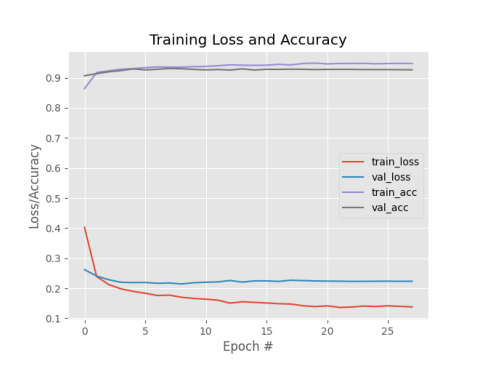

In [ ]:
# Entrenamos el clasificador nuevo o recuperamos sus pesos.
efficientNetB0 = EfficientNetB0_model(
    name="EfficientNetB0",
    epochs=30,
    batch_size=BATCH_SIZE,
    train_ds=train_ds,
    val_ds=val_ds,
    test_ds=test_ds
)

efficientNetB0.build()

if not efficientNetB0.load():
    efficientNetB0.train()

if (MODELS / "EfficientNetB0.png").exists():
    efficientNetB0.show_history()

In [ ]:
# Evaluacion de EfficientNetB0.
loss_effnet_base, accuracy_effnet_base = efficientNetB0.model.evaluate(
    efficientNetB0.test_ds,
    verbose=1
)

print(f"EfficientNetB0 - Test Loss: {loss_effnet_base:.4f}")
print(f"EfficientNetB0 - Test Accuracy: {accuracy_effnet_base:.4f}")

y_true_effnet_base, y_pred_effnet_base = efficientNetB0.evaluate()
efficientNetB0.display_confusion_matrix(y_true_effnet_base, y_pred_effnet_base)
efficientNetB0.print_classification_report(y_true_effnet_base, y_pred_effnet_base)


### 4.2. Fine-tuning

En esta segunda fase hemos realizado un ajuste fino (*fine-tuning*) de EfficientNetB0, descongelando sus últimas 30 capas para permitir que el modelo adapte parte de los pesos preentrenados a las características de nuestro conjunto de datos.

Hemos mantenido congeladas las capas `BatchNormalization` para conservar sus estadísticas y evitar alteraciones durante el entrenamiento. Además, hemos reducido la tasa de aprendizaje respecto a la fase anterior, con el objetivo de realizar ajustes progresivos en los pesos del modelo sin modificar bruscamente los conocimientos adquiridos durante el preentrenamiento.

Por último, hemos guardado los pesos y la gráfica correspondientes a esta fase por separado, de manera que podamos distinguir los resultados del *fine-tuning* de los obtenidos durante la extracción de características.

In [ ]:
fine_tuning_weights_effnet = MODELS / "EfficientNetB0_finetuned.weights.h5"
fine_tuning_plot_effnet = MODELS / "EfficientNetB0_finetuned.png"

# Descongelamos solo el bloque final y mantenemos BatchNormalization congelada.
efficientNetB0.base_network.trainable = True
fine_tune_at_effnet = max(0, len(efficientNetB0.base_network.layers) - 30)

for layer in efficientNetB0.base_network.layers[:fine_tune_at_effnet]:
    layer.trainable = False

for layer in efficientNetB0.base_network.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

if fine_tuning_weights_effnet.exists():
    efficientNetB0.model.load_weights(fine_tuning_weights_effnet)
    print("Pesos del fine-tuning de EfficientNetB0 recuperados.")
else:
    efficientNetB0.model.compile(
        optimizer=Adam(learning_rate=1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history_finetuning_effnet = efficientNetB0.model.fit(
        efficientNetB0.train_ds,
        validation_data=efficientNetB0.val_ds,
        epochs=20,
        callbacks=[
            EarlyStopping(
                monitor="val_accuracy",
                patience=5,
                mode="max",
                restore_best_weights=True
            ),
            ReduceLROnPlateau(
                monitor="val_accuracy",
                factor=0.5,
                patience=3,
                mode="max",
                min_lr=1e-7
            )
        ]
    )

    efficientNetB0.model.save_weights(fine_tuning_weights_effnet)
    efficientNetB0.plot_history(history_finetuning_effnet)
    import shutil
    shutil.copyfile(
        MODELS / "EfficientNetB0.png",
        fine_tuning_plot_effnet
    )

if fine_tuning_plot_effnet.exists():
    plt.figure(figsize=(6, 6))
    plt.imshow(Image.open(fine_tuning_plot_effnet))
    plt.axis("off")
    plt.show()

### 4.3. Evaluación con fine-tuning y resultados de ambas fases

Hemos evaluado la versión ajustada de EfficientNetB0 utilizando el mismo conjunto de test que en la fase de extracción de características. De esta forma, podemos comparar los resultados obtenidos en ambas fases bajo las mismas condiciones.

En la siguiente tabla recogemos las métricas de pérdida (*loss*) y exactitud (*accuracy*) de EfficientNetB0 antes y después de aplicar *fine-tuning*. Esta comparación nos permitirá valorar si el ajuste de las últimas capas del modelo ha supuesto una mejora en la clasificación de las imágenes.

En este apartado nos centramos exclusivamente en los resultados de EfficientNetB0. La comparación con el resto de modelos utilizados en el proyecto se realizará en la sección 5.

### 4.4. Análisis de las curvas de aprendizaje y sobreajuste

En las gráficas de EfficientNetB0 durante la fase de *feature extraction*, la *accuracy* de entrenamiento aumenta y la pérdida de entrenamiento disminuye a lo largo de las épocas. Las curvas de validación también mejoran respecto al inicio: la *val_accuracy* pasa de 90,69 % a 92,65 %, mientras que la *val_loss* baja de 0,2618 a 0,2232. Esto indica que el modelo aprende características útiles y que la mejora no se limita al conjunto de entrenamiento.

Hacia el final, sin embargo, las métricas de validación dejan de mejorar al mismo ritmo que las de entrenamiento: la *val_accuracy* alcanza su máximo (93,11 %) en la época 8 y termina en 92,65 %, y la *val_loss* llega a un mínimo de 0,2143 en la época 9 antes de acabar en 0,2232. Por tanto, observamos una brecha moderada y señales de **sobreajuste leve en las últimas épocas**, aunque no una divergencia marcada: las métricas finales de validación siguen siendo buenas y mejores que al comienzo. Para elegir el punto de entrenamiento conviene priorizar el mínimo de *val_loss* o aplicar *early stopping*.

En la fase de *fine-tuning* no se han guardado en el notebook las curvas ni el historial de entrenamiento y validación. En consecuencia, no podemos confirmar ni descartar el sobreajuste de esa fase a partir de las gráficas disponibles; las métricas del conjunto de test por sí solas no bastan para determinarlo. Sería necesario conservar y representar `history_finetune` para realizar esa comparación.

94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.9169 - loss: 0.2210
EfficientNetB0 con fine-tuning - Test Loss: 0.2210
EfficientNetB0 con fine-tuning - Test Accuracy: 0.9169
94/94 ━━━━━━━━━━━━━━━━━━━━ 14s 76ms/step


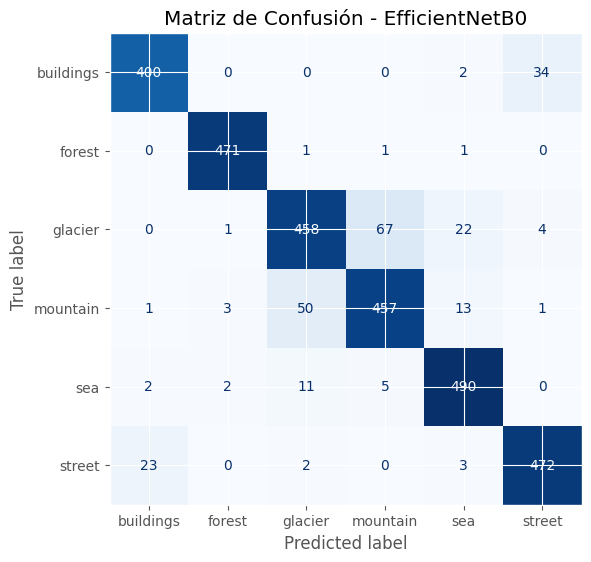

              precision    recall  f1-score   support

   buildings     0.9390    0.9174    0.9281       436
      forest     0.9874    0.9937    0.9905       474
     glacier     0.8774    0.8297    0.8529       552
    mountain     0.8623    0.8705    0.8664       525
         sea     0.9228    0.9608    0.9414       510
      street     0.9237    0.9440    0.9337       500

    accuracy                         0.9169      2997
   macro avg     0.9188    0.9193    0.9188      2997
weighted avg     0.9165    0.9169    0.9165      2997



,Fase,Test loss,Test accuracy
0,Sin fine-tuning,0.227297,0.913247
1,Con fine-tuning,0.220958,0.916917


In [ ]:
loss_effnet_finetuned, accuracy_effnet_finetuned = efficientNetB0.model.evaluate(
    efficientNetB0.test_ds,
    verbose=1
)

print(f"EfficientNetB0 con fine-tuning - Test Loss: {loss_effnet_finetuned:.4f}")
print(f"EfficientNetB0 con fine-tuning - Test Accuracy: {accuracy_effnet_finetuned:.4f}")

y_true_effnet_finetuned, y_pred_effnet_finetuned = efficientNetB0.evaluate()
efficientNetB0.display_confusion_matrix(y_true_effnet_finetuned, y_pred_effnet_finetuned)
efficientNetB0.print_classification_report(y_true_effnet_finetuned, y_pred_effnet_finetuned)

resultados_effnet = pd.DataFrame({
    "Fase": ["Sin fine-tuning", "Con fine-tuning"],
    "Test loss": [loss_effnet_base, loss_effnet_finetuned],
    "Test accuracy": [accuracy_effnet_base, accuracy_effnet_finetuned]
})
display(resultados_effnet)

# 5. Comparación global y conclusiones

## 5.1. Comparación de los modelos

Comparamos los resultados de la ejecución más reciente sobre las mismas 2.997 imágenes del conjunto de test. Para las CNN entrenadas desde cero, la salida disponible es el informe de clasificación, que no incluye la pérdida. Los valores de EfficientNetB0 proceden de la tabla de evaluación de sus dos fases.

| Estrategia | Modelo y configuración | Test loss | Accuracy (%) | Macro-F1 (%) | Weighted-F1 (%) |
|---|---|---:|---:|---:|---:|
| Desde cero | CNN simple | — | 88,49 | 88,63 | 88,46 |
| Desde cero | CNN simple con data augmentation | — | 87,05 | 87,09 | 86,99 |
| Desde cero | CNN v2 con Batch Normalization y Dropout | — | 89,19 | 89,30 | 89,15 |
| Desde cero | CNN residual con regularización L2 | — | 90,42 | 90,54 | 90,39 |
| Transfer learning + fine-tuning | MobileNetV2 | 0,2284 | **92,56** | **92,68** | **92,52** |
| Transfer learning | EfficientNetB0, base congelada | 0,2273 | 91,32 | — | — |
| Transfer learning + fine-tuning | EfficientNetB0 | **0,2210** | 91,69 | 91,88 | 91,65 |

Las métricas F1 se expresan como porcentajes y proceden de los informes de clasificación guardados. Para EfficientNetB0 con la base congelada solo se dispone de pérdida y accuracy, por lo que no se informan valores F1.

## 5.2. Análisis comparativo

- Entre las CNN entrenadas desde cero, la CNN residual con regularización L2 obtiene el mejor resultado, con un 90,42 % de accuracy y un 90,54 % de macro-F1.
- El *data augmentation* no mejora la CNN simple en esta ejecución: la accuracy baja del 88,49 % al 87,05 % (1,44 puntos porcentuales).
- MobileNetV2 con *fine-tuning* alcanza la mayor accuracy (92,56 %) y el mayor macro-F1 (92,68 %). Supera en 2,14 puntos porcentuales de accuracy a la CNN residual.
- El *fine-tuning* de EfficientNetB0 mejora la accuracy de 91,32 % a 91,69 % (0,37 puntos porcentuales) y reduce la pérdida de 0,2273 a 0,2210.
- EfficientNetB0 con *fine-tuning* obtiene la menor pérdida de test, pero MobileNetV2 presenta mayor accuracy y F1; por tanto, MobileNetV2 ofrece el mejor rendimiento global en clasificación.
- En el informe de MobileNetV2, `glacier` presenta el menor recall (82,79 %), mientras que `forest` alcanza un recall del 99,79 %. Las escenas de glaciares son comparativamente más difíciles de reconocer y merecen un análisis de sus confusiones con otras categorías.

## 5.3. Conclusión

En esta ejecución, MobileNetV2 con *fine-tuning* es el modelo con mejores resultados globales: alcanza un 92,56 % de accuracy y un 92,68 % de macro-F1 sobre las 2.997 imágenes de test. La CNN residual con regularización L2 es la alternativa más sólida entre las redes entrenadas desde cero (90,42 % de accuracy), aunque queda por debajo de MobileNetV2.

EfficientNetB0 también mejora con *fine-tuning* y registra la menor pérdida de test (0,2210), pero no supera a MobileNetV2 en accuracy ni en F1. La elección depende, por tanto, del criterio: MobileNetV2 es preferible si se prioriza el rendimiento de clasificación, mientras que EfficientNetB0 con *fine-tuning* presenta la pérdida más baja.

Estas cifras reflejan las evaluaciones registradas en esta ejecución. Dado que se consultaron los resultados del conjunto de test para comparar varias configuraciones, la selección puede verse influida por esas consultas. Para una evaluación más rigurosa, convendría seleccionar el modelo con el conjunto de validación y reservar el conjunto de test para una única medición.